# TS08 — Quantiles, residual simulation and chronological interval calibration

## Goal
Build and evaluate forecast distributions for **both** future causal smoothed log
levels and actual cumulative future log returns. Separate point forecasts, predictive
intervals, simultaneous five-horizon bands and uncertainty in historical performance.
Coverage alone is insufficient: width, interval score, weighted interval score,
pinball loss and CRPS measure additional aspects of probabilistic forecasts.

## Observed results

Both tracks were evaluated on **239 scored origins per horizon** using only matured prequential calibration errors. For **smoothed**, the volatility-scaled 80% five-session interval covers **80.8%**, with mean width **345.0 log bps**. For **returns**, the volatility-scaled 80% five-session interval covers **77.8%**, with mean width **691.8 log bps**. For the same scaled method, Ridge five-session WIS skill versus its track null is smoothed: -0.1464, returns: -0.1188; the null distributions score better in this sample. Coverage, width and proper-score comparisons are shown separately. Nominal levels are not guarantees under stock-data dependence or shifts; the latest snapshot forecast remains unscored.

## Setup
Use the existing NumPy/pandas/SciPy/scikit-learn notebook environment. No new packages,
pretrained weights or market data are required. TS08 runs independently from the
bundled adjusted SPY snapshot ending 2026-10-01. Earlier notebooks remain unchanged.
The snapshot was examined repeatedly; chronological replay does not make it an
untouched test. This notebook chooses no winning method for deployment.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src'/'tslab').is_dir())
sys.path.insert(0,str(ROOT/'src'))
from dataclasses import asdict,replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display,Markdown
from tslab.data import load_snapshot
from tslab.supervised import FeatureSpec
from tslab.probabilistic import (LEVELS,QUANTILES,METHODS,ProbabilitySpec,pinball,interval_score,
    weighted_interval_score,empirical_crps,gaussian_crps,rank_radius,
    point_ledger,probabilistic_replay,simulation_controls)
from tslab.reporting import configure_plots,save_figure,write_manifest
configure_plots();SEED=1731
OUT=ROOT/'outputs'/'TS08_Probabilistic_Forecasts_and_Calibration';OUT.mkdir(parents=True,exist_ok=True)
market_x,metadata=load_snapshot(ROOT/'inputs'/'SPY_adjusted_demo.csv',ROOT/'inputs'/'SPY_adjusted_demo.metadata.json')
features=FeatureSpec();settings=ProbabilitySpec()
colors=dict(zip(METHODS,['#0072B2','#E69F00','#009E73','#D55E00','#CC79A7']))
print('Snapshot:',market_x.index[0].date(),'to',market_x.index[-1].date(),'; observations:',len(market_x))
display(pd.DataFrame([asdict(settings)]))

Snapshot: 2018-01-02 to 2026-10-01 ; observations: 2199


,forecast_start,evaluation_start,evaluation_step,max_samples,calibration_window,scale_window
0,650,1000,5,252,126,60


## Steps
### 1. Define what is being calibrated and scored
A fixed direct **Ridge_10** predicts the same five targets and uses the same
20 × 2 smoothed-change inputs as TS05–TS07. It is a teaching choice, not promoted
because it won earlier outer scores. Fit it separately for each track on at most
252 mature examples. Include filter-aware unchanged-price and zero-return nulls.
The uncertainty methods can be applied to other prequential forecast ledgers later.

Issue forecasts **daily** from observed position 650. At origin $t$, use the last
126 issued forecast-error vectors whose **entire five-horizon outcome** is known:
$j+5\le t$. An error is $e_{j,h}=y_{j+h}-\hat y_{j,h}$ from the forecast issued
at $j$, not an in-sample residual of a model fitted at $t$. Calibration is delayed
by five sessions even for horizon one so all methods use the same complete vectors.
After-close $t$ permits outcomes ending at $t$. Model-training and calibration pools
can overlap in dates; residuals are prequential and no exchangeable split is claimed.

| Method | Distribution or interval construction | Limitation |
|---|---|---|
| gaussian | Current point + past error mean; error SD; Gaussian quantiles | Gaussian, locally stable errors assumed as an approximation |
| empirical | Current point + each of 126 historical five-error vectors | Discrete residual CDF; limited tail resolution; not new price-process paths |
| rank_absolute | Symmetric radius from absolute errors, rank $\lceil(n+1)c\rceil$ | Conformal-style rank correction, without exchangeability guarantee here |
| rank_scaled | Apply the same rank to $|e_{j,h}|/v_{j,h}$, multiply by $v_{t,h}$ | Scale is a causal smoothed-input proxy, not a known conditional SD |
| joint_max_scaled | Rank the maximum normalized error over all five horizons | Intended for a five-horizon rectangular band; separate joint coverage check |

The scale proxy uses RMS fast-EMA changes over the last 60 observed sessions, floored
at $10^{-6}$. Horizon factors are $\sqrt h$ for returns and
$\sqrt{\sum_{k=1}^h(1-0.8^k)^2}$ for smoothed levels. These resemble IID-innovation
shapes; the RMS proxy is not an estimate with a proved conditional variance identity.
Past normalization uses the scale available at each **past** forecast origin.
With 126 vectors, a 2.5% empirical tail has only about 3.15 observations; tail
estimates are coarse even before serial dependence reduces the effective information.

Report central 50/80/95% intervals and quantiles 0.025/0.1/0.25/0.5/0.75/0.9/0.975.
Gaussian/empirical residual corrections can shift the median away from the point
forecast. The two rank intervals stay centered at that point. Quantiles are residual-
distribution forecasts, not separately trained conditional quantile regressions.

In [2]:
checks=pd.DataFrame([
    {'check':'pinball: y=3, q=.8 quantile=1','value':float(pinball(3,1,.8)),'expected':1.6},
    {'check':'80% interval [0,1], y=2','value':float(interval_score(2,0,1,.8)),'expected':11.},
    {'check':'N(0,1) CRPS at y=0','value':float(gaussian_crps(0,1,0)),'expected':(np.sqrt(2)-1)/np.sqrt(np.pi)},
    {'check':'95% rank with scores 0..125','value':float(rank_radius(np.arange(126.),.95)),'expected':120.}])
np.testing.assert_allclose(checks.value,checks.expected,atol=1e-12)
assert np.isinf(rank_radius(np.arange(9.),.95))
checks.to_csv(OUT/'analytic_score_checks.csv',index=False);display(checks.round(6))
# Exact empirical CDF score checked against the double-sum formula.
samples=np.array([-2.,0.,1.,4.]);y=.3
brute=np.mean(abs(samples-y))-.5*np.mean(abs(samples[:,None]-samples[None,:]))
assert abs(empirical_crps(samples,y)-brute)<1e-12
print('PASS: elementary scores, corrected ranks and empirical CRPS identity.')

PASS: elementary scores, corrected ranks and empirical CRPS identity.


,check,value,expected
0,"pinball: y=3, q=.8 quantile=1",1.600000,1.600000
1,"80% interval [0,1], y=2",11.000000,11.000000
2,"N(0,1) CRPS at y=0",0.233695,0.233695
3,95% rank with scores 0..125,120.000000,120.000000


### 2. Check independent controls and a deliberate distribution shift
Generate 200 independent replicates, each with 126 calibration vectors and 500
independent test vectors. Five IID Gaussian innovations generate cumulative returns
and EMA forecast errors using their exact horizon weights. These independent
vectors are an idealized control, unlike overlapping stock forecasts.

In the IID control, a continuous exchangeable absolute score has rank coverage
$k/(n+1)$ **averaged over calibration samples**, with $k=\lceil(n+1)c\rceil$.
A given calibration realization need not have exactly that coverage. Joint-max
uses a scale estimated from the calibration sample, so no exact exchangeable-rank
identity is asserted for that scaled joint statistic. Its coverage is measured.

Then multiply all test innovations by three while leaving calibration unchanged.
Historical absolute-error intervals should under-cover. An **oracle** that knows the
scale jump can adjust the interval; the stock-data proxy has no such knowledge.
These are teaching controls, not parameter selection or market evidence.

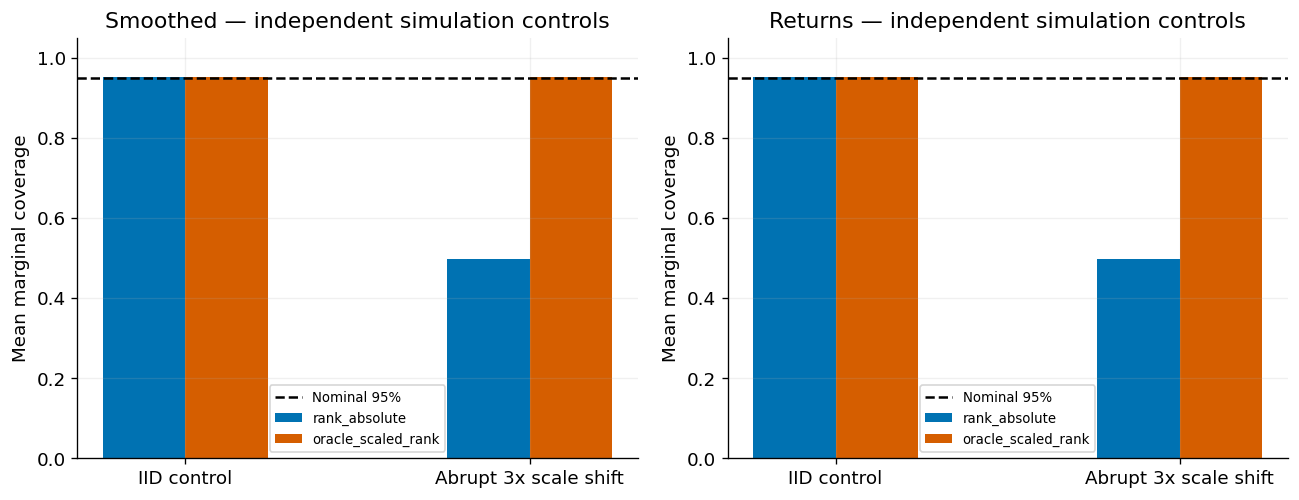

,track,case,method,level,mean_marginal_coverage,mean_joint_coverage,sd_replicate_coverage,mean_width
8,returns,Abrupt 3x scale shift,rank_absolute,0.95,0.4969,0.1249,0.0288,6.7458
17,returns,IID,rank_absolute,0.95,0.9525,0.8623,0.0145,6.7458
26,smoothed,Abrupt 3x scale shift,rank_absolute,0.95,0.4980,0.2267,0.0340,2.5952
35,smoothed,IID,rank_absolute,0.95,0.9527,0.8957,0.0166,2.5952


In [3]:
controls=simulation_controls(seed=SEED,repetitions=200,calibration_n=126,test_n=500)
controls.to_csv(OUT/'simulation_replicates.csv',index=False)
summary=controls.groupby(['track','case','method','level']).agg(
    mean_marginal_coverage=('marginal_coverage','mean'),
    mean_joint_coverage=('joint_coverage','mean'),
    sd_replicate_coverage=('marginal_coverage','std'),mean_width=('mean_width','mean')).reset_index()
summary.to_csv(OUT/'simulation_summary.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
for ax,track in zip(axes,['smoothed','returns']):
    part=summary[(summary.track==track)&(summary.level==.95)]
    for method,offset in [('rank_absolute',-.12),('oracle_scaled_rank',.12)]:
        values=part[part.method==method].set_index('case').loc[['IID','Abrupt 3x scale shift']]
        ax.bar(np.arange(2)+offset,values.mean_marginal_coverage,width=.24,label=method)
    ax.axhline(.95,color='black',ls='--',label='Nominal 95%')
    ax.set_xticks([0,1],['IID control','Abrupt 3x scale shift'])
    ax.set(title=f'{track.title()} — independent simulation controls',ylabel='Mean marginal coverage',ylim=(0,1.05));ax.legend(fontsize=8)
save_figure(fig,OUT,'01_iid_and_shift_controls');
display(summary.query("method=='rank_absolute' and level==.95").round(4))

### 3. Replay issued forecasts and calibrate only mature errors
The outer score cohort starts at position 1000, every five observed sessions, ending
where **all five outcomes** are present, plus the latest wholly unscored forecast.
This gives 239 scored origins per horizon in the bundled snapshot. Calibration uses
daily forecasts, so its 126 examples span roughly half a trading year, not 126 times
five sessions. Adjacent calibration residuals overlap; scored origins also share
training/calibration windows. The sample size is not an independent-observation count.

No shuffled split, retrospective reselection or tuning of the uncertainty method is
used. Stock intervals have no asserted finite-sample coverage guarantee: refitted
models, serial dependence and regime shifts undermine ordinary exchangeable conformal
arguments. The delay-aware online conformal literature addresses additional procedures;
this simple rolling implementation does not implement their adaptive guarantees.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS08_Probabilistic_Forecasts_and_Calibration/02_marginal_calibration.png')


,origin,origin_pos,track,model,calibration_n,calibration_first_origin_pos,calibration_last_origin_pos,calibration_last_label_pos,scale_available_pos
0,2021-12-21,1000,returns,Ridge_10,126,870,995,1000,1000
1,2021-12-29,1005,returns,Ridge_10,126,875,1000,1005,1005
2,2022-01-05,1010,returns,Ridge_10,126,880,1005,1010,1010
3,2022-01-12,1015,returns,Ridge_10,126,885,1010,1015,1015


,track,model,n,RMSE,MSE_skill
8,returns,Ridge_10,239,0.02638,-0.23834
9,returns,zero,239,0.02370,0.00000
18,smoothed,Ridge_10,239,0.01304,-0.30275
19,smoothed,filter_nochange,239,0.01143,0.00000


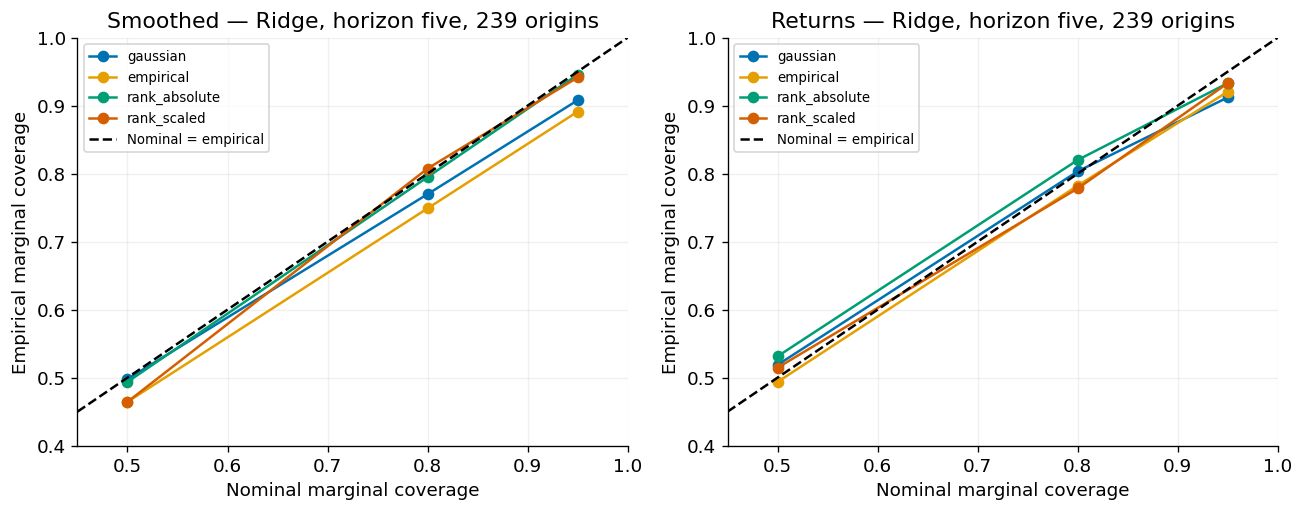

In [4]:
ledger,fit_audit,dataset=point_ledger(market_x,settings,features)
ledger.to_csv(OUT/'issued_forecast_ledger.csv',index=False)
fit_audit.to_csv(OUT/'fit_audit.csv',index=False)
run=probabilistic_replay(ledger,settings)
for name,frame in run.items():frame.to_csv(OUT/f'{name}.csv',index=False)
for track in ['smoothed','returns']:
    run['point_scorecard'].query('track==@track').to_csv(OUT/f'{track}_scorecard.csv',index=False)
intervals=run['intervals'];card=run['interval_scorecard'];scored=intervals[intervals.status=='scored']
display(run['calibration_audit'].head(4))
display(run['point_scorecard'].query('horizon==5')[['track','model','n','RMSE','MSE_skill']].round(5))
fig,axes=plt.subplots(1,2,figsize=(11,4.4))
for ax,track in zip(axes,['smoothed','returns']):
    part=card[(card.track==track)&(card.model=='Ridge_10')&(card.horizon==5)]
    for method in METHODS[:-1]:
        values=part[part.method==method].sort_values('level')
        ax.plot(values.level,values.coverage,'o-',color=colors[method],label=method)
    ax.plot([.45,1],[.45,1],'k--',label='Nominal = empirical')
    ax.set(title=f'{track.title()} — Ridge, horizon five, 239 origins',xlabel='Nominal marginal coverage',ylabel='Empirical marginal coverage',xlim=(.45,1),ylim=(.4,1));ax.legend(fontsize=8)
save_figure(fig,OUT,'02_marginal_calibration');

### 4. Balance coverage against width and proper scores
An extremely wide interval can cover nearly everything and remain unhelpful.
For central coverage $c=1-\alpha$, the interval score is
$$IS_\alpha=(u-l)+\frac{2}{\alpha}(l-y)_++\frac{2}{\alpha}(y-u)_+.$$
It penalizes width and misses. Smaller scores are better.

For the three central intervals plus median, use
$$WIS=\frac{0.5|y-m|+\sum_k(\alpha_k/2)IS_{\alpha_k}}{K+0.5}.$$
WIS is a proper quantile score when interpreted at those quantile levels. The
rank intervals are symmetric quantile candidates; their nominal calibration is
not assumed to be correct. Joint-max bands target a different joint event, so
we do **not** label their scalar interval score or WIS as proper joint scores.

Pinball loss is $\rho_\tau(y-q)=(\tau-1\{y<q\})(y-q)$, without the optional
factor of two used by some texts. CRPS uses the complete Gaussian CDF or the exact
126-atom empirical CDF, $E|X-y|-\tfrac12E|X-X'|$. No full CDF is supplied for rank
intervals, so their CRPS remains missing, not zero. The finite empirical CDF CRPS
is used, not the alternative unbiased ensemble score. All these scores are in
log units; widths and example errors are multiplied by 10,000 for log basis points.
Distribution skill is $1-\mathrm{WIS}_{Ridge}/\mathrm{WIS}_{null}$ using the same
uncertainty method and paired origins; positive is better. Each null receives its
own past forecast errors for calibration, rather than inheriting Ridge errors.

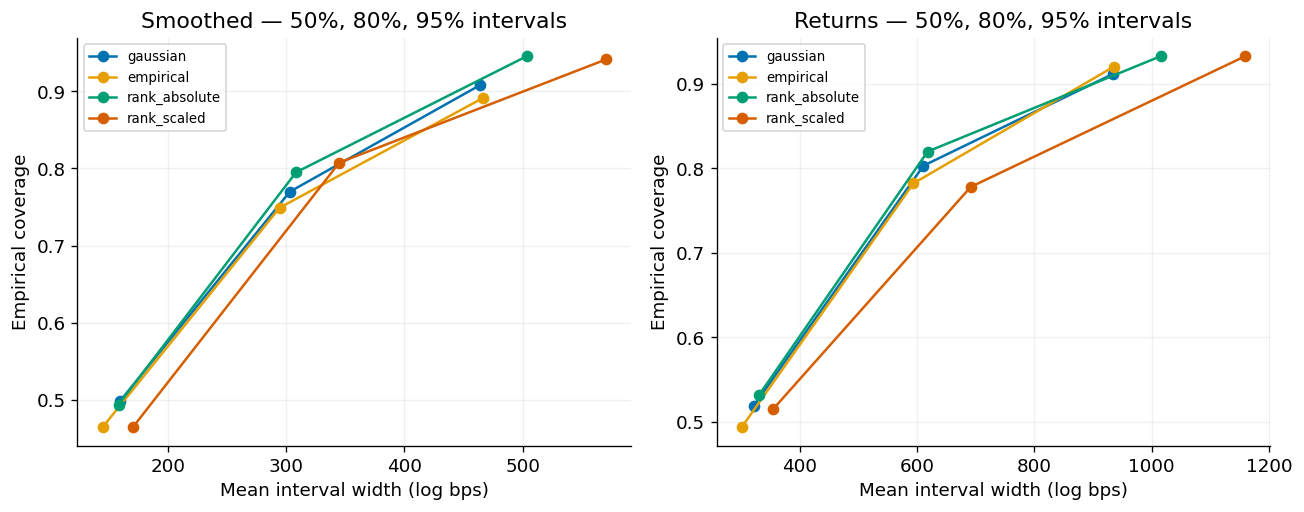

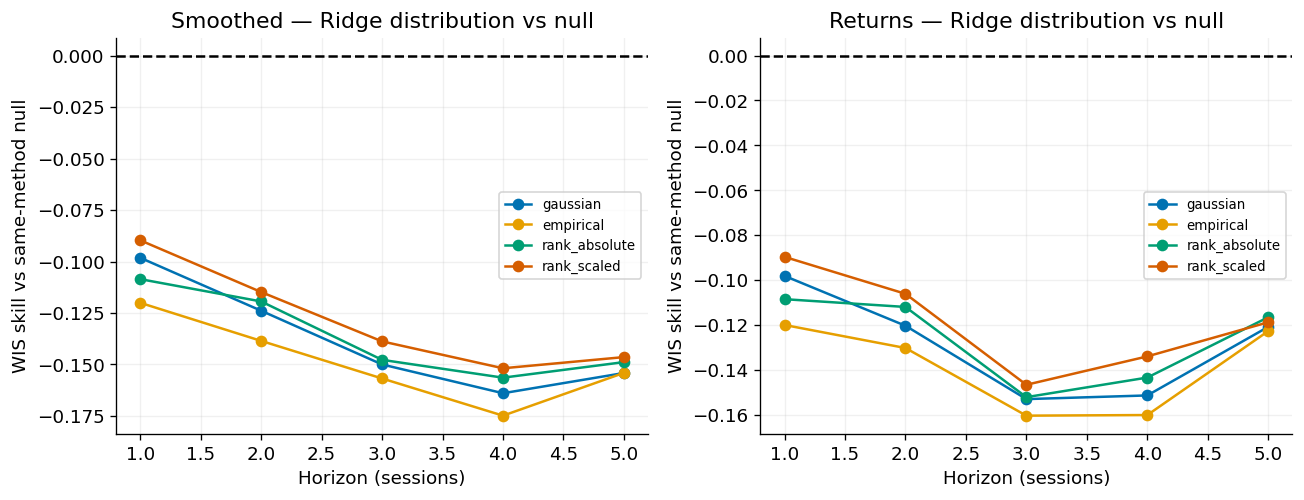

,track,model,method,horizon,n,WIS,CRPS
4,returns,Ridge_10,empirical,5,239,0.011308,0.014460
9,returns,Ridge_10,gaussian,5,239,0.011252,0.014413
14,returns,Ridge_10,rank_absolute,5,239,0.011029,NaN
19,returns,Ridge_10,rank_scaled,5,239,0.011139,NaN
24,returns,zero,empirical,5,239,0.010071,0.012868
29,returns,zero,gaussian,5,239,0.010038,0.012871
34,returns,zero,rank_absolute,5,239,0.009877,NaN
39,returns,zero,rank_scaled,5,239,0.009955,NaN
44,smoothed,Ridge_10,empirical,5,239,0.005634,0.007218
49,smoothed,Ridge_10,gaussian,5,239,0.005629,0.007208


,track,method,WIS_skill,CRPS_skill
4,smoothed,empirical,-0.15409,-0.15894
9,smoothed,gaussian,-0.15415,-0.15387
14,smoothed,rank_absolute,-0.14886,NaN
19,smoothed,rank_scaled,-0.14642,NaN
24,returns,empirical,-0.12279,-0.12369
29,returns,gaussian,-0.12090,-0.11983
34,returns,rank_absolute,-0.11661,NaN
39,returns,rank_scaled,-0.11885,NaN


In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4.4))
for ax,track in zip(axes,['smoothed','returns']):
    part=card[(card.track==track)&(card.model=='Ridge_10')&(card.horizon==5)&(card.method!='joint_max_scaled')]
    for method in METHODS[:-1]:
        values=part[part.method==method].sort_values('level')
        ax.plot(values.mean_width*1e4,values.coverage,'o-',color=colors[method],label=method)
    ax.set(title=f'{track.title()} — 50%, 80%, 95% intervals',xlabel='Mean interval width (log bps)',ylabel='Empirical coverage');ax.legend(fontsize=8)
save_figure(fig,OUT,'03_coverage_width_tradeoff');
distribution_card=run['distribution_scorecard']
skill_rows=[]
for track,baseline in [('smoothed','filter_nochange'),('returns','zero')]:
    a=distribution_card.query('track==@track and model=="Ridge_10"')
    b=distribution_card.query('track==@track and model==@baseline')
    paired=a.merge(b,on=['track','method','horizon'],suffixes=('_ridge','_null'),validate='one_to_one')
    assert paired.n_ridge.eq(paired.n_null).all()
    paired['WIS_skill']=1-paired.WIS_ridge/paired.WIS_null
    paired['CRPS_skill']=1-paired.CRPS_ridge/paired.CRPS_null
    skill_rows.append(paired)
distribution_skill=pd.concat(skill_rows,ignore_index=True)
distribution_skill.to_csv(OUT/'distribution_skill.csv',index=False)

fig,axes=plt.subplots(1,2,figsize=(11,4.3))
for ax,track in zip(axes,['smoothed','returns']):
    for method in METHODS[:-1]:
        part=distribution_skill.query('track==@track and method==@method')
        ax.plot(part.horizon,part.WIS_skill,'o-',color=colors[method],label=method)
    ax.axhline(0,color='black',ls='--')
    ax.set(title=f'{track.title()} — Ridge distribution vs null',xlabel='Horizon (sessions)',ylabel='WIS skill vs same-method null');ax.legend(fontsize=8)
save_figure(fig,OUT,'04_weighted_interval_scores');
display(distribution_card.query('horizon==5').round(6))
display(distribution_skill.query('horizon==5')[["track","method","WIS_skill","CRPS_skill"]].round(5))

### 5. Distinguish marginal intervals from simultaneous five-horizon bands
Five marginal 95% intervals do not form a simultaneous 95% band. If events were
independent, joint coverage would be 0.95^5 ≈ 0.774; horizons here are dependent,
so even that calculation is only a counterexample, not a forecast of joint coverage.
The joint-max method ranks the maximum normalized error of each complete historical
five-vector. It generally widens the rectangle. Evaluate the event that **all five
future targets** lie within it, separately from marginal coverage.

The empirical method resamples entire historical five-error vectors, preserving
their within-vector dependence under the assumed residual mixture. Independently
resampling each horizon would destroy that dependence. It does not generate a
structurally fitted future stock-price process or couple the two research tracks.

Samples describe the frozen historical snapshot origin, not a live forecast for today.


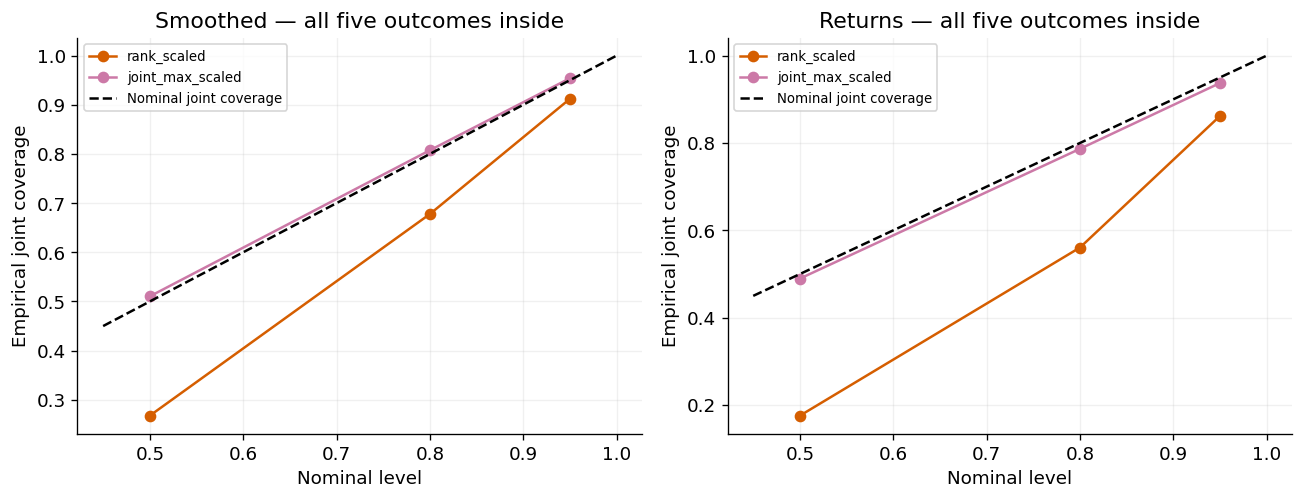

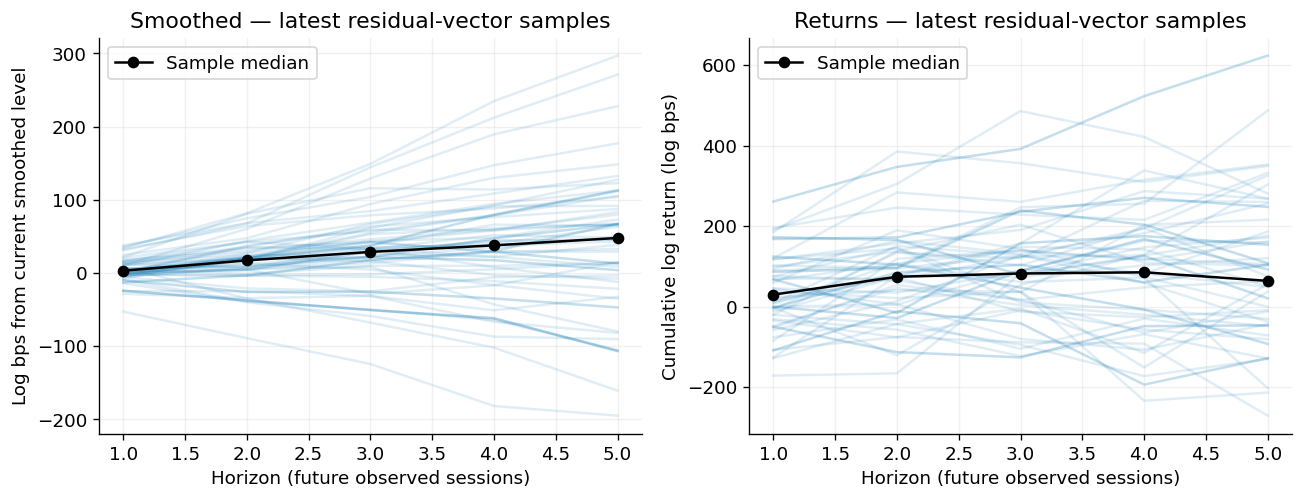

In [6]:
paths=run['joint_coverage']
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
for ax,track in zip(axes,['smoothed','returns']):
    for method in ['rank_scaled','joint_max_scaled']:
        part=paths.query('track==@track and model=="Ridge_10" and method==@method').sort_values('level')
        ax.plot(part.level,part.joint_coverage,'o-',color=colors[method],label=method)
    ax.plot([.45,1],[.45,1],'k--',label='Nominal joint coverage')
    ax.set(title=f'{track.title()} — all five outcomes inside',xlabel='Nominal level',ylabel='Empirical joint coverage');ax.legend(fontsize=8)
save_figure(fig,OUT,'05_marginal_vs_joint');
latest_samples=run['latest_empirical_samples'];rng=np.random.default_rng(SEED)
# One common row index across horizons per sample; never resample columns separately.
bootstrap=[]
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
for ax,track in zip(axes,['smoothed','returns']):
    native=latest_samples.query('track==@track and model=="Ridge_10"').pivot(index='sample_id',columns='horizon',values='prediction_sample')
    draw_ids=rng.integers(0,settings.calibration_window,size=1000)
    draws=native.to_numpy()[draw_ids]
    anchor=dataset.smoothed.iloc[-1] if track=='smoothed' else 0.
    ax.plot(range(1,6),(draws[:60]-anchor).T*1e4,color='#0072B2',alpha=.12)
    ax.plot(range(1,6),np.median(draws-anchor,axis=0)*1e4,'o-',color='black',label='Sample median')
    ax.set(title=f'{track.title()} — latest residual-vector samples',xlabel='Horizon (future observed sessions)',ylabel='Log bps from current smoothed level' if track=='smoothed' else 'Cumulative log return (log bps)');ax.legend()
    for j,values in enumerate(draws):
        for h in range(1,6):bootstrap.append({'track':track,'model':'Ridge_10','draw_id':j,'native_sample_id':int(draw_ids[j]),'horizon':h,'sample':values[h-1]})
pd.DataFrame(bootstrap).to_csv(OUT/'latest_bootstrap_draws.csv',index=False)
save_figure(fig,OUT,'06_latest_residual_simulation');
print('Samples describe the frozen historical snapshot origin, not a live forecast for today.')

### 6. Check local coverage and sensitivity without choosing a winner
Overall coverage can hide a period of under-coverage. Show a trailing 40-scored-
origin coverage estimate, requiring all 40 observations, for Ridge's 80% five-session
interval. It is a descriptive dependent series, not a coverage confidence band.

Recompute interval summaries using 252 rather than 126 daily calibration errors,
with identical point forecasts, outer dates and methods. This doubles the history
but can react more slowly to changes. Both windows are reported; outer scores do
not select a preferred calibration window. The score cohort differs from TS04–TS07,
so these point or distribution scores must not be compared directly with their
30-origin summaries without an explicit matched-date analysis.

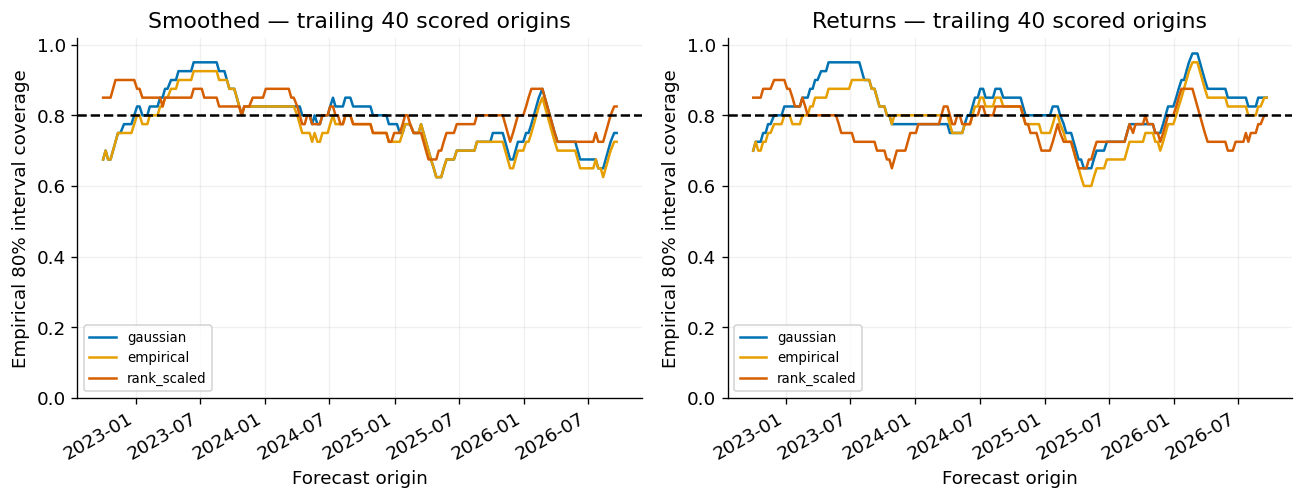

,track,method,calibration_window,n,coverage,mean_width,mean_interval_score
13,returns,empirical,126,239,0.78243,0.05941,0.09566
28,returns,gaussian,126,239,0.80335,0.06112,0.09531
43,returns,joint_max_scaled,126,239,0.89958,0.09690,NaN
58,returns,rank_absolute,126,239,0.82008,0.06183,0.09303
73,returns,rank_scaled,126,239,0.77824,0.06918,0.09669
163,smoothed,empirical,126,239,0.74895,0.02945,0.04860
178,smoothed,gaussian,126,239,0.76987,0.03033,0.04847
193,smoothed,joint_max_scaled,126,239,0.88703,0.04309,NaN
208,smoothed,rank_absolute,126,239,0.79498,0.03085,0.04690
223,smoothed,rank_scaled,126,239,0.80753,0.03450,0.04636


In [7]:
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
for ax,track in zip(axes,['smoothed','returns']):
    part=scored.query('track==@track and model=="Ridge_10" and horizon==5 and level==.8')
    for method in ['gaussian','empirical','rank_scaled']:
        values=part[part.method==method].sort_values('origin')
        ax.plot(values.origin,values.covered.rolling(40,min_periods=40).mean(),color=colors[method],label=method)
    ax.axhline(.8,color='black',ls='--')
    ax.set(title=f'{track.title()} — trailing 40 scored origins',xlabel='Forecast origin',ylabel='Empirical 80% interval coverage',ylim=(0,1.02));ax.legend(fontsize=8)
fig.autofmt_xdate();save_figure(fig,OUT,'07_local_coverage');
sensitivity=probabilistic_replay(ledger,replace(settings,calibration_window=252))
comparison=pd.concat([card.assign(calibration_window=126),sensitivity['interval_scorecard'].assign(calibration_window=252)],ignore_index=True)
comparison.to_csv(OUT/'calibration_window_sensitivity.csv',index=False)
display(comparison.query('model=="Ridge_10" and horizon==5 and level==.8')[['track','method','calibration_window','n','coverage','mean_width','mean_interval_score']].round(5))

## Checks
Audit each training cutoff and calibration cutoff, both tracks, interval nesting,
quantile ordering, latest-label immaturity and identical cohorts. The package tests
also poison future observations and immature errors, and compare scoring functions
with independent elementary formulas. The saved-artifact verifier reconstructs
calibration slices and bounds from the issued ledger.

In [8]:
assert (fit_audit.max_training_label<=fit_audit.origin_pos).all()
audit=run['calibration_audit']
assert audit.calibration_n.eq(settings.calibration_window).all()
assert (audit.calibration_last_label_pos<=audit.origin_pos).all()
assert (intervals.lower<=intervals.upper).all()
assert card.n.eq(239).all()
assert intervals.query('origin_pos==@ledger.origin_pos.max()').status.eq('immature').all()
q=run['quantiles'].pivot(index=['origin','track','model','method','horizon'],columns='tau',values='quantile')
assert (np.diff(q.to_numpy(),axis=1)>=0).all()
assert run['distribution_scorecard'].query('method in ["rank_absolute","rank_scaled"]').CRPS.isna().all()
config={'features':asdict(features),'probability':asdict(settings),'levels':list(LEVELS),'quantiles':list(QUANTILES),
    'point_model':'fixed Ridge_10, direct, alpha=10; paired null per track',
    'methods':list(METHODS),'sensitivity_windows':[126,252],
    'simulation':{'seed':SEED,'repetitions':200,'calibration_vectors':126,'test_vectors':500}}
manifest=write_manifest(OUT,config,{'market':metadata},seed=SEED)
manifest['scope']='milestone_5_prequential_probability_and_interval_calibration'
manifest['claims']='Exploratory single-snapshot forecast distributions; no exchangeable coverage guarantee or trading edge'
from importlib.metadata import version
manifest['versions']['scikit-learn']=version('scikit-learn')
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
summary='## Observed results'+chr(10)*2+'Both tracks were evaluated on **239 scored origins per horizon** using only matured prequential calibration errors. '
for track in ['smoothed','returns']:
    row=card.query('track==@track and model=="Ridge_10" and method=="rank_scaled" and horizon==5 and level==.8').iloc[0]
    summary+=f'For **{track}**, the volatility-scaled 80% five-session interval covers **{row.coverage:.1%}**, with mean width **{row.mean_width*1e4:.1f} log bps**. '
summary+='For the same scaled method, Ridge five-session WIS skill versus its track null is ' + ', '.join(f"{r.track}: {r.WIS_skill:.4f}" for r in distribution_skill.query("method=='rank_scaled' and horizon==5").itertuples()) + '; the null distributions score better in this sample. '
summary+='Coverage, width and proper-score comparisons are shown separately. Nominal levels are not guarantees under stock-data dependence or shifts; the latest snapshot forecast remains unscored.'
(OUT/'observed_summary.md').write_text(summary)
print('PASS: mature training/calibration, complete paired cohorts, ordered intervals/quantiles and unscored latest origin.')

PASS: mature training/calibration, complete paired cohorts, ordered intervals/quantiles and unscored latest origin.


## Next Steps
TS09 will address cross-dataset and cross-asset benchmarking with explicit independent-
evaluation rules. GARCH/conditional-volatility models, conditional quantile learners,
adaptive conformal updates with delayed feedback, distributional neural objectives
and prospective calibration can extend this uncertainty layer in separate experiments.

Primary methodology references:
[Forecasting: Principles and Practice — distributional accuracy](https://otexts.com/fpp3/toolbox.html#evaluating-distributional-forecast-accuracy),
[Bracher et al. — interval formats and WIS](https://arxiv.org/abs/2005.12881),
[Gibbs and Candès — adaptive conformal inference](https://arxiv.org/abs/2106.00170),
[Hallberg Szabadváry — delayed multistep conformal inference](https://proceedings.mlr.press/v230/hallberg-szabadvary24a.html).
TS08 implements the documented rolling rank methods, not the cited adaptive algorithms.